# Multicomponent Vapor–Liquid Equilibrium: Raoult, Modified Raoult and γ–Φ

A Python companion to the MATLAB solver in [`../matlab`](../matlab). It ports the four VLE calculations, checks them
against the MATLAB results for all 180 project cases, and extends the project with:

1. **Flash calculations** (the assignment's bonus part, not done in the original submission)
2. A **validation** of the model against the known acetone–methanol azeotrope
3. A look at a **model limitation**: the nearly immiscible benzene–water pair

**Models.** Phase equilibrium in the γ–Φ formulation is $y_i \Phi_i P = x_i \gamma_i P_i^\text{sat}$:

- **RL (Raoult's law):** $\gamma_i = \Phi_i = 1$
- **MRL (modified Raoult's law):** $\Phi_i = 1$, with Wilson activity coefficients
- **γ–Φ:** Wilson activity coefficients, plus fugacity coefficients from the virial equation (Pitzer correlation)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

comp = pd.read_csv("../data/components.csv", index_col="name")
a_all = pd.read_csv("../data/wilson_aij.csv", index_col=0)
comp

,antoine_A,antoine_B,antoine_C,omega,Tc_K,Pc_bar,Zc,Vc_cm3_per_mol
name,,,,,,,,
acetone,14.3145,2756.22,228.060,0.307,508.2,47.01,0.233,209.0
methanol,16.5785,3638.27,239.500,0.564,512.6,80.97,0.224,118.0
water,16.3872,3885.70,230.170,0.345,647.1,220.55,0.229,55.9
methyl acetate,14.2456,2662.78,219.690,0.331,506.6,47.50,0.257,228.0
benzene,13.7819,2726.81,217.572,0.210,562.2,48.98,0.271,259.0


## 1. Model

In [2]:
class System:
    def __init__(self, names):
        c = comp.loc[names]
        self.names = list(names)
        self.A, self.B, self.C = c.antoine_A.values, c.antoine_B.values, c.antoine_C.values
        self.w, self.Tc, self.Pc, self.Zc, self.Vc = (c[k].values for k in ["omega", "Tc_K", "Pc_bar", "Zc", "Vc_cm3_per_mol"])
        self.a = a_all.loc[names, names].values

    def psat(self, T):                     # kPa, T in degC
        return np.exp(self.A - self.B / (T + self.C))

    def tsat(self, P, i):                  # degC
        return self.B[i] / (self.A[i] - np.log(P)) - self.C[i]

    def gamma(self, x, T, method):
        if method == "RL":
            return np.ones_like(x)
        Tk = T + 273.15
        V = self.Vc * self.Zc ** ((1 - Tk / self.Tc) ** (2 / 7))
        L = (V[None, :] / V[:, None]) * np.exp(-self.a / (1.9872 * Tk))   # L[i,j] = Vj/Vi exp(-aij/RT)
        S = L @ x
        return np.exp(1 - np.log(S) - L.T @ (x / S))

    def phi(self, y, P, T, Psat, method):
        if method != "GP":
            return np.ones_like(y)
        Tk, Rb = T + 273.15, 83.14
        w = (self.w[:, None] + self.w[None, :]) / 2
        Tc = np.sqrt(np.outer(self.Tc, self.Tc))
        Zc = (self.Zc[:, None] + self.Zc[None, :]) / 2
        Vc = ((self.Vc[:, None] ** (1/3) + self.Vc[None, :] ** (1/3)) / 2) ** 3
        Pc = Zc * Rb * Tc / Vc
        Tr = Tk / Tc
        B = (0.083 - 0.422 / Tr**1.6 + w * (0.139 - 0.172 / Tr**4.2)) * Rb * Tc / Pc * 1e-6   # m3/mol
        d = 2 * B - np.diag(B)[:, None] - np.diag(B)[None, :]
        mix = 2 * y.sum() * (d.T @ y) - y @ d @ y
        return np.exp((np.diag(B) * (P - Psat) + 0.5 * P * mix) / (8.314e-3 * Tk))


def bubble_P(s, x, T, m):
    Psat, g, Phi = s.psat(T), s.gamma(x, T, m), np.ones_like(x)
    P = np.sum(x * g * Psat / Phi)
    for _ in range(200):
        y = x * g * Psat / (Phi * P)
        Phi = s.phi(y, P, T, Psat, m)
        P_new = np.sum(x * g * Psat / Phi)
        if abs(P_new - P) < 1e-8 * P_new:
            return P_new, x * g * Psat / (Phi * P_new)
        P = P_new
    raise RuntimeError("bubble P did not converge")

def converge_gamma(s, y, Phi, P, Psat, g, T, m):
    for _ in range(500):
        x = y * Phi * P / (g * Psat)
        g_new = s.gamma(x / x.sum(), T, m)
        if np.max(np.abs(g_new - g)) < 1e-10:
            return g_new
        g = g_new
    raise RuntimeError("gamma loop did not converge")

def dew_P(s, y, T, m):
    Psat, g, Phi = s.psat(T), np.ones_like(y), np.ones_like(y)
    P = 1 / np.sum(y * Phi / (g * Psat))
    g = s.gamma(y * Phi * P / (g * Psat), T, m)
    P = 1 / np.sum(y * Phi / (g * Psat))
    for _ in range(200):
        Phi = s.phi(y, P, T, Psat, m)
        g = converge_gamma(s, y, Phi, P, Psat, g, T, m)
        P_new = 1 / np.sum(y * Phi / (g * Psat))
        if abs(P_new - P) < 1e-8 * P_new:
            return P_new, y * Phi * P_new / (g * Psat)
        P = P_new
    raise RuntimeError("dew P did not converge")

def bubble_T(s, x, P, m, j=0):
    Phi = np.ones_like(x)
    T = np.sum(x * np.array([s.tsat(P, i) for i in range(len(x))]))
    for _ in range(500):
        Psat, g = s.psat(T), s.gamma(x, T, m)
        T_new = s.tsat(P / np.sum(x * g / Phi * Psat / Psat[j]), j)
        Psat = s.psat(T_new)
        Phi = s.phi(x * g * Psat / (Phi * P), P, T_new, Psat, m)
        if abs(T_new - T) < 1e-8:
            g, Psat = s.gamma(x, T_new, m), s.psat(T_new)
            return T_new, x * g * Psat / (Phi * P)
        T = T_new
    raise RuntimeError("bubble T did not converge")

def dew_T(s, y, P, m, j=0):
    Phi, g = np.ones_like(y), np.ones_like(y)
    T = np.sum(y * np.array([s.tsat(P, i) for i in range(len(y))]))
    for _ in range(500):
        Psat = s.psat(T)
        Phi = s.phi(y, P, T, Psat, m)
        g = converge_gamma(s, y, Phi, P, Psat, g, T, m)
        T_new = s.tsat(P * np.sum(y * Phi / g * Psat[j] / Psat), j)
        if abs(T_new - T) < 1e-8:
            return T_new, y * Phi * P / (g * s.psat(T_new))
        T = T_new
    raise RuntimeError("dew T did not converge")

SOLVERS = {"BUBL P": bubble_P, "DEW P": dew_P, "BUBL T": bubble_T, "DEW T": dew_T}

## 2. Cross-check against the MATLAB results (all 180 project cases)

In [3]:
SYSTEMS = {"System 1": ["acetone", "methanol", "water"],
           "System 2": ["methyl acetate", "benzene", "water"],
           "System 3": ["acetone", "methanol", "benzene"]}

ml = pd.read_csv("../results/project_cases.csv")
dv, dc = [], []
for r in ml.itertuples():
    s = System(SYSTEMS[r.system])
    v, w = SOLVERS[r.calculation](s, np.array([r.z1, r.z2, r.z3]), r.T_or_P_given, r.method)
    dv.append(abs(v - r.result) / r.result)
    dc.append(np.max(np.abs(w - [r.w1, r.w2, r.w3])))
print(f"{len(ml)} cases | max relative difference in P or T: {max(dv):.1e} | max difference in composition: {max(dc):.1e}")

180 cases | max relative difference in P or T: 4.4e-15 | max difference in composition: 2.4e-15


## 3. Results at the base composition (0.3 / 0.4 / 0.3)

Pressures in kPa (at 70 °C) and temperatures in °C (at 150 kPa) for the three formulations.

In [4]:
base = ml[(ml.z1 == 0.3) & ml.T_or_P_given.isin([70, 150])]
pivot = base.pivot_table(index=["system", "calculation"], columns="method", values="result", sort=False)[["RL", "MRL", "GP"]]
pivot["MRL vs RL (%)"] = 100 * (pivot.MRL / pivot.RL - 1)
pivot["GP vs MRL (%)"] = 100 * (pivot.GP / pivot.MRL - 1)
pivot.round(2)

method                    RL     MRL      GP  MRL vs RL (%)  GP vs MRL (%)
system   calculation                                                      
System 1 BUBL P       106.74  138.74  138.77          29.98           0.02
         DEW P         68.01   85.06   85.44          25.08           0.44
         BUBL T        79.92   72.31   72.30          -9.52          -0.02
         DEW T         91.01   84.56   84.40          -7.09          -0.19
System 2 BUBL P        85.83   84.03   83.48          -2.10          -0.65
         DEW P         59.02   57.37   57.09          -2.80          -0.48
         BUBL T        87.67   88.51   88.79           0.95           0.32
         DEW T         96.58   97.31   97.55           0.75           0.25
System 3 BUBL P       119.47  176.85  180.06          48.03           1.81
         DEW P        108.96  175.40  178.88          60.98           1.98
         BUBL T        76.78   65.15   64.70         -15.14          -0.70
         DEW T         79.62   65.44   64.95         -17.82          -0.75

- **Liquid non-ideality matters far more than vapour non-ideality.** Moving from RL to MRL changes pressures by up to
  **60 %** (System 3) and temperatures by up to 14 °C. Adding vapour fugacity coefficients (MRL → γ–Φ) changes them by
  **less than 2 %**: at 70–150 kPa, the vapour is nearly ideal.
- **Systems 1 and 3 show positive deviations** from Raoult's law (γ > 1), so the mixture boils at a higher pressure, or
  a lower temperature, than Raoult's law predicts.
- **System 2 shows almost no deviation.** That is suspicious for a mixture containing benzene and water (see Section 6).

## 4. Extension: flash calculations (the bonus part)

For a feed $z$ at given $T$ and $P$ between the dew and bubble points, the vapour fraction $V$ solves the
Rachford–Rice equation $\sum_i z_i (K_i-1)/(1+V(K_i-1)) = 0$ with $K_i = \gamma_i P_i^\text{sat}/(\Phi_i P)$.
$\gamma(x)$ and $\Phi(y)$ are updated until $V$ converges. Following Table 1 of the assignment, $T$ is taken as the
average of the bubble and dew temperatures at the given $P$.

In [5]:
def rachford_rice(z, K):
    # Solve on the full 'negative flash' interval (Whitson & Michelsen), so that
    # intermediate iterations near an azeotrope cannot lose the root.
    if K.max() <= 1: return 0.0
    if K.min() >= 1: return 1.0
    lo, hi = 1 / (1 - K.max()), 1 / (1 - K.min())
    eps = 1e-12 * (hi - lo)
    return brentq(lambda v: np.sum(z * (K - 1) / (1 + v * (K - 1))), lo + eps, hi - eps)

def flash(s, z, T, P, m):
    Psat = s.psat(T)
    Pb, y_b = bubble_P(s, z, T, m)
    Pd, x_d = dew_P(s, z, T, m)
    if not Pd < P < Pb:
        raise ValueError("feed is not two-phase at these conditions")
    V = (Pb - P) / (Pb - Pd)                         # initial guess: interpolate between dew and bubble
    x = (1 - V) * z + V * x_d; y = (1 - V) * y_b + V * z
    for _ in range(1000):
        g, Phi = s.gamma(x / x.sum(), T, m), s.phi(y / y.sum(), P, T, Psat, m)
        K = g * Psat / (Phi * P)
        V_new = rachford_rice(z, K)
        x = z / (1 + V_new * (K - 1)); y = K * x
        if abs(V_new - V) < 1e-10:
            if not 0 < V_new < 1:
                raise RuntimeError("flash converged outside the two-phase region")
            return V_new, x, y
        V = V_new
    raise RuntimeError("flash did not converge")

rows = []
for sys_name, names in SYSTEMS.items():
    s = System(names)
    for P, z in [(150, [0.3, 0.4, 0.3]), (300, [0.3, 0.4, 0.3]), (450, [0.3, 0.4, 0.3]),
                 (150, [0.4, 0.4, 0.2]), (150, [0.5, 0.4, 0.1])]:
        z = np.array(z)
        T = 0.5 * (bubble_T(s, z, P, "GP")[0] + dew_T(s, z, P, "GP")[0])
        V, x, y = flash(s, z, T, P, "GP")
        rows.append(dict(system=sys_name, P_kPa=P, z=f"{z[0]:.1f}/{z[1]:.1f}/{z[2]:.1f}", T_C=T, V=V,
                         x1=x[0], x2=x[1], x3=x[2], y1=y[0], y2=y[1], y3=y[2]))
flash_table = pd.DataFrame(rows)
flash_table.round(4)

,system,P_kPa,z,T_C,V,x1,x2,x3,y1,y2,y3
0,System 1,150,0.3/0.4/0.3,78.3487,0.6980,0.1232,0.3449,0.5319,0.3765,0.4238,0.1997
1,System 1,300,0.3/0.4/0.3,99.3277,0.6995,0.1517,0.3495,0.4988,0.3637,0.4217,0.2146
2,System 1,450,0.3/0.4/0.3,112.9815,0.6964,0.1711,0.3516,0.4773,0.3562,0.4211,0.2227
3,System 1,150,0.4/0.4/0.2,74.1742,0.7468,0.2251,0.3970,0.3779,0.4593,0.4010,0.1397
4,System 1,150,0.5/0.4/0.1,70.1754,0.7460,0.3878,0.4326,0.1796,0.5382,0.3889,0.0729
5,System 2,150,0.3/0.4/0.3,93.1726,0.5804,0.2633,0.3019,0.4347,0.3265,0.4709,0.2026
6,System 2,300,0.3/0.4/0.3,117.7655,0.5635,0.2707,0.3236,0.4056,0.3227,0.4592,0.2181
7,System 2,450,0.3/0.4/0.3,134.1118,0.5539,0.2751,0.3351,0.3898,0.3200,0.4523,0.2277
8,System 2,150,0.4/0.4/0.2,88.4586,0.5716,0.3303,0.3561,0.3137,0.4523,0.4329,0.1148
9,System 2,150,0.5/0.4/0.1,82.8303,0.6017,0.4019,0.4208,0.1772,0.5649,0.3862,0.0489


At the mid-point temperature, **55–81 % of the feed vaporizes**, not 50 %. The vapour fraction does not grow
linearly between the bubble and dew points. The vapour is enriched in the more volatile components (acetone, methyl
acetate) and the liquid in water. System 3 is close to azeotropic: its two-phase window is only 0.1–0.8 °C wide, and the
two phases have similar compositions. This is the regime where flash calculations are numerically hardest.

## 5. Validation: the acetone–methanol azeotrope

The Wilson model should reproduce the well-known **minimum-boiling azeotrope** of acetone and methanol at 1 atm.
Literature values are about 55.5–55.7 °C at roughly 80 mol % acetone.

Predicted azeotrope (gamma-phi, Wilson): 55.42 °C at x_acetone = 0.788


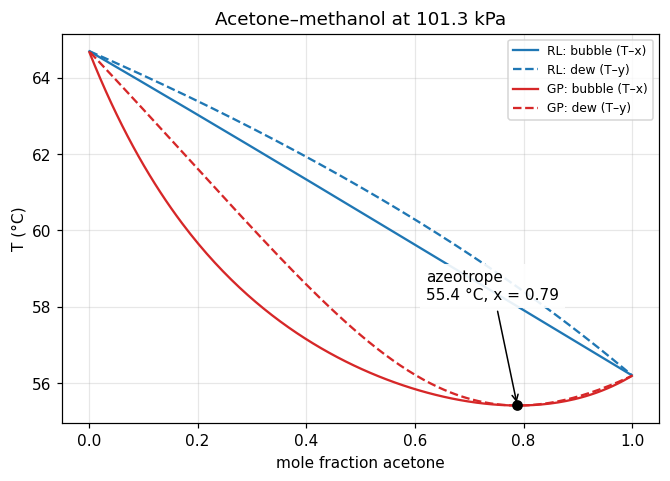

In [6]:
s = System(["acetone", "methanol"])
xs = np.linspace(0.001, 0.999, 200)
res = {m: np.array([bubble_T(s, np.array([x, 1 - x]), 101.325, m) for x in xs], dtype=object) for m in ["RL", "GP"]}

fig, ax = plt.subplots(figsize=(7, 4.6))
for m, color in [("RL", "C0"), ("GP", "C3")]:
    T = np.array([r[0] for r in res[m]]); y = np.array([r[1][0] for r in res[m]])
    ax.plot(xs, T, color=color, label=f"{m}: bubble (T–x)")
    ax.plot(y, T, color=color, ls="--", label=f"{m}: dew (T–y)")
T_gp = np.array([r[0] for r in res["GP"]]); y_gp = np.array([r[1][0] for r in res["GP"]])
i = np.argmin(np.abs(y_gp - xs))
ax.plot(xs[i], T_gp[i], "ko")
ax.annotate(f"azeotrope\n{T_gp[i]:.1f} °C, x = {xs[i]:.2f}", (xs[i], T_gp[i]), xytext=(0.62, 58.2),
            arrowprops=dict(arrowstyle="->"), bbox=dict(fc="white", ec="none", alpha=0.9))
ax.set(xlabel="mole fraction acetone", ylabel="T (°C)", title="Acetone–methanol at 101.3 kPa")
ax.legend(fontsize=8, loc="upper right")
fig.savefig("../figures/acetone_methanol_azeotrope.png", dpi=150, bbox_inches="tight")
print(f"Predicted azeotrope (gamma-phi, Wilson): {T_gp[i]:.2f} °C at x_acetone = {xs[i]:.3f}")

The γ–Φ model with these Wilson parameters predicts the azeotrope close to the literature values. Raoult's law
cannot predict an azeotrope at all: its bubble and dew curves only meet at the pure components.

## 6. Limitation: benzene and water are (almost) immiscible

Benzene dissolves in water only to about $x \approx 4 \times 10^{-4}$ at 25 °C (≈ 1.8 g/L). For a nearly immiscible
solute, $\gamma^\infty \approx 1/x^\text{sat}$, so the real infinite-dilution activity coefficient of benzene in water
is of order **2000–2500**. What does the Wilson model with the given parameters predict?

In [7]:
s = System(["benzene", "water"])
for T in [25, 70]:
    g_b = s.gamma(np.array([1e-9, 1 - 1e-9]), T, "MRL")[0]
    g_w = s.gamma(np.array([1 - 1e-9, 1e-9]), T, "MRL")[1]
    print(f"T = {T} °C: gamma_inf(benzene in water) = {g_b:.2f}, gamma_inf(water in benzene) = {g_w:.2f}")

T = 25 °C: gamma_inf(benzene in water) = 7.41, gamma_inf(water in benzene) = 6.35
T = 70 °C: gamma_inf(benzene in water) = 6.74, gamma_inf(water in benzene) = 4.41


The model predicts activity coefficients of order 1–10, **more than two orders of magnitude too small**. This is a known
structural limit: the Wilson equation **cannot predict liquid–liquid phase splitting**. A real benzene–water mixture
at the System 2 compositions would separate into an organic and an aqueous liquid phase, which would require a VLLE
calculation (for example with NRTL or UNIQUAC parameters fitted to LLE data). The System 2 results should therefore
be read as a numerical exercise, not as a physical prediction. Systems 1 and 3 are fully miscible and well described
by Wilson.